# PDF → ảnh → tiền xử lý → PaddleOCR-VL → JSON (chạy một lượt, không cần restart)

**Cách tránh restart:** PaddlePaddle-GPU được cài vào một **venv riêng** (`/content/venv-paddle`) và chạy bằng subprocess. Môi trường Python chính của Colab (torch, nvidia-*) không bị đụng tới, nên không còn xung đột NCCL và không cần `os.kill`.

Chỉ cần: bật GPU (Runtime → Change runtime type → T4) rồi **Run all**.

| Phần | Chạy ở đâu |
|---|---|
| PDF → ảnh, tiền xử lý, chuẩn hóa JSON, vẽ bbox | kernel chính |
| PaddleOCR-VL (layout + VLM) | venv riêng, gọi bằng subprocess, nạp model **một lần** cho cả file |

Kết quả: `work/document.json` (block gồm `type`, `bbox`, `text`) và JSON gốc của Paddle trong `work/ocr_raw/`.

## 1. Cấu hình

In [2]:
from pathlib import Path

PDF_PATH   = "input.pdf"       # nếu file chưa có, cell kế tiếp sẽ mở hộp thoại upload (Colab)
WORK_DIR   = Path("work")
DPI        = 200
MAX_SIDE   = 2500              # giới hạn cạnh dài nhất sau tiền xử lý (px)
PAGES      = None              # None = tất cả; hoặc [0, 1, 2] (đánh số từ 0)

DO_DESKEW        = True
DO_SHADOW_REMOVE = True

# PaddleOCR-VL (giữ như file VLM_OCR.ipynb của bạn)
PIPELINE_VERSION = "v1.5"
VL_MODEL         = "PaddleOCR-VL-1.5-0.9B"
LAYOUT_MODEL     = "PP-DocLayoutV3"

FORCE_OCR = False              # True = chạy lại OCR cả những trang đã có JSON

VENV_DIR     = Path("/content/venv-paddle")
VENV_PY      = VENV_DIR / "bin" / "python"
IMG_DIR_RAW  = WORK_DIR / "pages_raw"
IMG_DIR_PRE  = WORK_DIR / "pages_pre"
RAW_JSON_DIR = WORK_DIR / "ocr_raw"
for d in (IMG_DIR_RAW, IMG_DIR_PRE, RAW_JSON_DIR):
    d.mkdir(parents=True, exist_ok=True)

if not Path(PDF_PATH).exists():
    try:
        from google.colab import files
        up = files.upload()
        PDF_PATH = next(iter(up))
    except ImportError:
        raise FileNotFoundError(f"Không thấy {PDF_PATH}")
print("PDF:", PDF_PATH)

Saving NCKH.pdf to NCKH.pdf
PDF: NCKH.pdf


## 2. Cài đặt (không cần restart)
- Kernel chính chỉ cài thêm vài gói nhẹ chưa được nạp (`uv`, `pymupdf`, `python-docx`).
- Venv Paddle chỉ tạo **nếu chưa có**, nên chạy lại notebook trong cùng phiên sẽ bỏ qua bước này. Lần đầu mất vài phút (gói GPU khá nặng). Colab xóa đĩa khi hết phiên, nên phiên mới sẽ cài lại.

In [3]:
!pip install -q uv pymupdf python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.6/20.6 MB 86.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 24.6 MB/s eta 0:00:00


In [4]:
%%bash
set -e
nvidia-smi -L || echo "CẢNH BÁO: không thấy GPU, Paddle sẽ chạy CPU (rất chậm)"

if [ ! -x /content/venv-paddle/bin/python ]; then
  uv venv /content/venv-paddle --python 3.12
  uv pip install --python /content/venv-paddle/bin/python \
      "paddlepaddle-gpu==3.2.1" --extra-index-url https://www.paddlepaddle.org.cn/packages/stable/cu126/
  uv pip install --python /content/venv-paddle/bin/python \
      "paddleocr[doc-parser]>=3.6.0" safetensors "tokenizers==0.22.2" "huggingface-hub>=0.25.0,<1.0"
else
  echo "venv-paddle đã có, bỏ qua cài đặt"
fi

# kiểm tra nhanh venv dùng được
/content/venv-paddle/bin/python -c "import paddle, paddleocr; print('paddle', paddle.__version__, '| CUDA build:', paddle.device.is_compiled_with_cuda()); print('paddleocr', paddleocr.__version__)"

GPU 0: Tesla T4 (UUID: GPU-4c79d216-b2f0-62c9-6887-716ad66a0a93)
paddle 3.2.1 | CUDA build: True
paddleocr 3.7.0


Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: venv-paddle
Activate with: source venv-paddle/bin/activate
Using Python 3.12.3 environment at: venv-paddle
Resolved 29 packages in 5.73s
Prepared 29 packages in 1m 26s
Installed 29 packages in 323ms
 + anyio==4.12.1
 + certifi==2026.1.4
 + h11==0.16.0
 + httpcore==1.0.9
 + httpx==0.28.1
 + idna==3.11
 + networkx==3.6.1
 + numpy==2.4.1
 + nvidia-cublas-cu12==12.6.4.1
 + nvidia-cuda-cccl-cu12==12.6.77
 + nvidia-cuda-cupti-cu12==12.6.80
 + nvidia-cuda-nvrtc-cu12==12.6.77
 + nvidia-cuda-runtime-cu12==12.6.77
 + nvidia-cudnn-cu12==9.5.1.17
 + nvidia-cufft-cu12==11.3.0.4
 + nvidia-cufile-cu12==1.11.1.6
 + nvidia-curand-cu12==10.3.7.77
 + nvidia-cusolver-cu12==11.7.1.2
 + nvidia-cusparse-cu12==12.5.4.2
 + nvidia-cusparselt-cu12==0.6.3
 + nvidia-nccl-cu12==2.25.1
 + nvidia-nvjitlink-cu12==12.6.85
 + nvidia-nvtx-cu12==12.6.77
 + opt-einsum==3.3.0
 + paddlepaddle-gpu==3.2.1
 + pillow==12.1.0
 + protobuf==6.

## 3. PDF → ảnh

In [5]:
import fitz  # PyMuPDF

def pdf_to_images(pdf_path, out_dir, dpi=200, pages=None):
    doc = fitz.open(pdf_path)
    idxs = range(len(doc)) if pages is None else pages
    zoom = dpi / 72
    paths = []
    for i in idxs:
        pix = doc[i].get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
        p = out_dir / f"page_{i+1:04d}.png"
        pix.save(p)
        paths.append(p)
    doc.close()
    return paths

raw_paths = pdf_to_images(PDF_PATH, IMG_DIR_RAW, DPI, PAGES)
print(f"Đã render {len(raw_paths)} trang")

Đã render 25 trang


## 4. Tiền xử lý ảnh
Làm sạch nhẹ, giữ màu, không nhị phân hóa: deskew góc nhỏ, khử bóng theo từng kênh, giới hạn kích thước.

Ảnh chụp điện thoại bị méo phối cảnh hoặc giấy cong cần thêm bước tìm 4 góc giấy / dewarp (chưa có ở đây).

In [6]:
import cv2
import numpy as np

def estimate_skew(gray, max_angle=5.0, step=0.25):
    h, w = gray.shape
    scale = 800 / max(h, w)
    small = cv2.resize(gray, (max(1, int(w*scale)), max(1, int(h*scale))), interpolation=cv2.INTER_AREA)
    bw = cv2.threshold(small, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    best_angle, best_score = 0.0, -1.0
    sh, sw = bw.shape
    for a in np.arange(-max_angle, max_angle + step, step):
        M = cv2.getRotationMatrix2D((sw/2, sh/2), a, 1.0)
        rot = cv2.warpAffine(bw, M, (sw, sh), flags=cv2.INTER_NEAREST)
        score = np.var(rot.sum(axis=1).astype(np.float64))
        if score > best_score:
            best_score, best_angle = score, a
    return float(best_angle)

def rotate_keep_size(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def remove_shadow(bgr):
    chans = []
    for c in cv2.split(bgr):
        dil = cv2.dilate(c, np.ones((7, 7), np.uint8))
        bg = cv2.medianBlur(dil, 21)
        diff = 255 - cv2.absdiff(c, bg)
        chans.append(cv2.normalize(diff, None, 0, 255, cv2.NORM_MINMAX))
    return cv2.merge(chans)

def preprocess(path, out_path):
    img = cv2.imread(str(path))
    info = {"skew_deg": 0.0, "shadow_removed": False, "resized": False}
    if DO_DESKEW:
        angle = estimate_skew(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
        if abs(angle) >= 0.3:
            img = rotate_keep_size(img, angle)
            info["skew_deg"] = angle
    if DO_SHADOW_REMOVE:
        img = remove_shadow(img)
        info["shadow_removed"] = True
    h, w = img.shape[:2]
    if max(h, w) > MAX_SIDE:
        s = MAX_SIDE / max(h, w)
        img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
        info["resized"] = True
    cv2.imwrite(str(out_path), img)
    info["width"], info["height"] = int(img.shape[1]), int(img.shape[0])
    return info

pre_info = {}
for p in raw_paths:
    pre_info[p.name] = preprocess(p, IMG_DIR_PRE / p.name)
    print(p.name, pre_info[p.name])

# Ảnh tiền xử lý thay đổi -> kết quả OCR cũ (nếu có) không còn khớp bbox
import json
(WORK_DIR / "pre_info.json").write_text(json.dumps(pre_info, indent=2), encoding="utf-8")

page_0001.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0002.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0003.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0004.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0005.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0006.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0007.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0008.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0009.png {'skew_deg': 0.0, 'shadow_removed': True, 'resized': False, 'width': 1653, 'height': 2339}
page_0010.png {'skew_deg': 0.0, 'shadow_removed': True,

3377

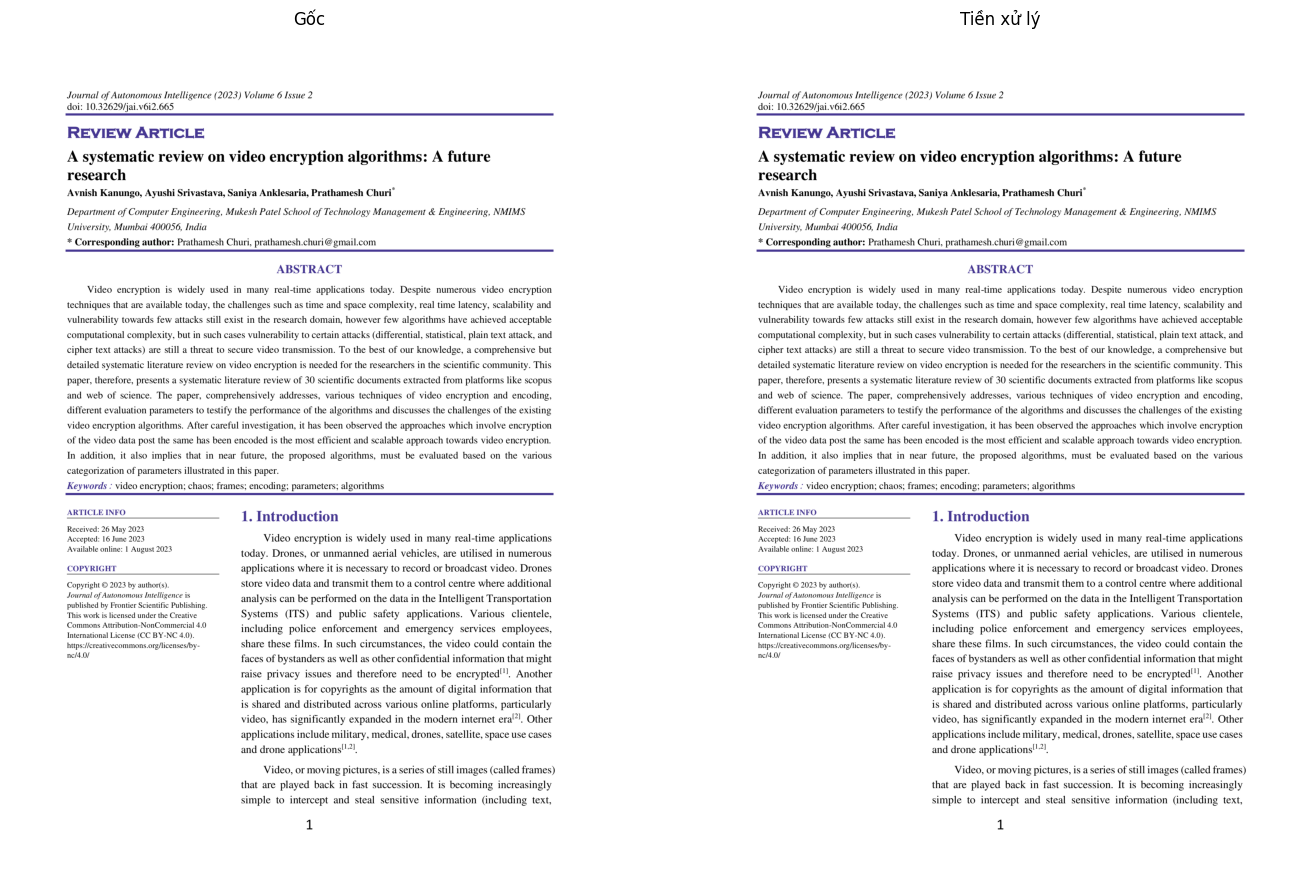

In [7]:
import matplotlib.pyplot as plt

k = 0
a = cv2.cvtColor(cv2.imread(str(raw_paths[k])), cv2.COLOR_BGR2RGB)
b = cv2.cvtColor(cv2.imread(str(IMG_DIR_PRE / raw_paths[k].name)), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(1, 2, figsize=(14, 9))
ax[0].imshow(a); ax[0].set_title("Gốc");        ax[0].axis("off")
ax[1].imshow(b); ax[1].set_title("Tiền xử lý"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 5. PaddleOCR-VL (chạy trong venv riêng)
Notebook ghi ra `ocr_batch.py` rồi gọi bằng Python của venv. Script nạp model **một lần** rồi xử lý lần lượt mọi trang, mỗi trang lưu một file JSON gốc.

- Trang nào đã có JSON sẽ được bỏ qua (chạy lại sau khi lỗi giữa chừng sẽ tiếp tục từ chỗ dở). Đặt `FORCE_OCR = True` để chạy lại tất cả, và **nên đặt khi bạn vừa đổi tiền xử lý**.
- Một trang lỗi không làm dừng cả file; lỗi được ghi vào `work/ocr_raw/page_xxxx.error.txt`.
- Log "use GQA ..." của Paddle rất dài nên được lọc bớt.

In [14]:
BATCH_SCRIPT = r'''
import sys, json, time, traceback
from pathlib import Path
from paddleocr import PaddleOCRVL

img_dir, raw_dir, version, vl_model, layout_model, force = sys.argv[1:7]
img_dir, raw_dir, force = Path(img_dir), Path(raw_dir), force == "1"

def to_jsonable(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    return str(o)

pages = sorted(img_dir.glob("page_*.png"))
todo = [p for p in pages if force or not (raw_dir / f"{p.stem}.json").exists()]
print(f"[batch] {len(pages)} trang, cần chạy {len(todo)}", flush=True)
if not todo:
    sys.exit(0)

t0 = time.time()
pipeline = PaddleOCRVL(
    pipeline_version=version,
    vl_rec_model_name=vl_model,
    layout_detection_model_name=layout_model,
    use_doc_orientation_classify=True,
    use_doc_unwarping=True,
)
print(f"[batch] nạp model xong sau {time.time()-t0:.0f}s", flush=True)

by_path = {str(p): p for p in todo}
remaining = list(todo)

def save(p, data, t):
    (raw_dir / f"{p.stem}.json").write_text(
        json.dumps(data, ensure_ascii=False, default=to_jsonable), encoding="utf-8")
    err = raw_dir / f"{p.stem}.error.txt"
    if err.exists():
        err.unlink()
    print(f"[batch] {p.name}: xong ({t:.0f}s kể từ lúc bắt đầu)", flush=True)

# Chế độ gộp: đưa cả danh sách trang vào MỘT lần predict. Với use_queues (mặc định) pipeline
# chạy song song theo luồng: nạp trang -> layout -> VLM, nên GPU ít phải chờ.
t1 = time.time()
try:
    for res in pipeline.predict([str(p) for p in todo]):
        data = res.json
        inner = data.get("res", data) if isinstance(data, dict) else {}
        p = by_path.get(inner.get("input_path")) or remaining[0]   # kết quả trả về theo thứ tự
        save(p, data, time.time() - t1)
        remaining.remove(p)
except Exception:
    print("[batch] lỗi ở chế độ gộp, chạy tiếp từng trang cho phần còn lại", flush=True)
    print(traceback.format_exc(), flush=True)

# Dự phòng: trang nào chưa xong thì chạy riêng từng trang, trang lỗi không làm dừng cả file
for p in list(remaining):
    t2 = time.time()
    try:
        res = list(pipeline.predict(str(p)))[0]
        save(p, res.json, time.time() - t2)
        remaining.remove(p)
    except Exception:
        (raw_dir / f"{p.stem}.error.txt").write_text(traceback.format_exc(), encoding="utf-8")
        print(f"[batch] {p.name}: LỖI (xem {p.stem}.error.txt)", flush=True)
'''
Path("ocr_batch.py").write_text(BATCH_SCRIPT, encoding="utf-8")

import subprocess

cmd = [str(VENV_PY), "ocr_batch.py", str(IMG_DIR_PRE), str(RAW_JSON_DIR),
       PIPELINE_VERSION, VL_MODEL, LAYOUT_MODEL, "1" if FORCE_OCR else "0"]

proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
tail = []
for line in proc.stdout:
    if "use GQA" in line:
        continue
    tail.append(line)
    tail = tail[-60:]
    if line.startswith("[batch]"):
        print(line, end="")
proc.wait()

if proc.returncode != 0:
    print("".join(tail))
    raise RuntimeError(f"ocr_batch.py thoát với mã {proc.returncode}, xem log ở trên")

errs = sorted(RAW_JSON_DIR.glob("*.error.txt"))
if errs:
    print("Các trang lỗi:", [e.name for e in errs])

[batch] 25 trang, cần chạy 0


## 6. Chuẩn hóa về `document.json`
`parsing_res_list` của Paddle đã theo thứ tự đọc, nên `order` lấy theo vị trí trong danh sách. `bbox` là tọa độ pixel trên **ảnh đã tiền xử lý** (`image`).

```json
{"id": "p1_b3", "order": 3, "type": "text", "bbox": [x1, y1, x2, y2], "text": "...", "empty": false}
```
Với `table`, `text` là HTML của bảng. Block có `empty: true` là block layout nhận ra nhưng VLM không đọc được chữ (ví dụ ô điền thông tin trống).

In [16]:
import json

def extract_blocks(raw, page_no):
    data = raw.get("res", raw) if isinstance(raw, dict) else {}
    items = data.get("parsing_res_list") or []
    blocks = []
    for i, it in enumerate(items):
        bbox = it.get("block_bbox")
        text = it.get("block_content") or ""
        blocks.append({
            "id": f"p{page_no}_b{i}",
            "order": i,
            "type": it.get("block_label") or "unknown",
            "bbox": [int(round(v)) for v in bbox] if bbox else None,
            "text": text,
            "empty": not text.strip(),
        })
    return blocks

pages_out, problems = [], []
for p in sorted(IMG_DIR_PRE.glob("page_*.png")):
    page_no = int(p.stem.split("_")[1])
    rj = RAW_JSON_DIR / f"{p.stem}.json"
    if not rj.exists():
        problems.append(f"{p.name}: chưa có kết quả OCR")
        continue
    raw = json.loads(rj.read_text(encoding="utf-8"))
    info = pre_info.get(p.name, {})
    data = raw.get("res", raw)
    # bbox chỉ đúng nếu ảnh OCR đã đọc cùng kích thước với ảnh đang lưu
    if data.get("width") and info.get("width") and (data["width"], data["height"]) != (info["width"], info["height"]):
        problems.append(f"{p.name}: kích thước OCR {data['width']}x{data['height']} khác ảnh {info['width']}x{info['height']} (hãy chạy lại với FORCE_OCR=True)")
    pages_out.append({
        "page": page_no,
        "image": str(p),
        "width": info.get("width"), "height": info.get("height"),
        "preprocess": {k: info[k] for k in ("skew_deg", "shadow_removed", "resized") if k in info},
        "blocks": extract_blocks(raw, page_no),
    })

document = {"source_pdf": str(PDF_PATH), "dpi": DPI, "pages": pages_out}
out_json = WORK_DIR / "document.json"
out_json.write_text(json.dumps(document, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu", out_json)
for pg in pages_out:
    n_empty = sum(b["empty"] for b in pg["blocks"])
    print(f"trang {pg['page']}: {len(pg['blocks'])} block ({n_empty} block rỗng)")
for m in problems:
    print("LƯU Ý:", m)

Đã lưu work/document.json
trang 1: 17 block (0 block rỗng)
trang 2: 12 block (0 block rỗng)
trang 3: 11 block (1 block rỗng)
trang 4: 8 block (1 block rỗng)
trang 5: 15 block (1 block rỗng)
trang 6: 13 block (0 block rỗng)
trang 7: 13 block (1 block rỗng)
trang 8: 14 block (0 block rỗng)
trang 9: 14 block (0 block rỗng)
trang 10: 12 block (0 block rỗng)
trang 11: 9 block (1 block rỗng)
trang 12: 12 block (0 block rỗng)
trang 13: 13 block (0 block rỗng)
trang 14: 10 block (0 block rỗng)
trang 15: 7 block (0 block rỗng)
trang 16: 12 block (0 block rỗng)
trang 17: 8 block (0 block rỗng)
trang 18: 8 block (0 block rỗng)
trang 19: 10 block (0 block rỗng)
trang 20: 10 block (0 block rỗng)
trang 21: 9 block (0 block rỗng)
trang 22: 4 block (0 block rỗng)
trang 23: 5 block (0 block rỗng)
trang 24: 21 block (0 block rỗng)
trang 25: 22 block (0 block rỗng)


## 7. Kiểm tra bằng mắt
Vẽ bbox lên ảnh (màu theo loại, số là thứ tự đọc). Nên xem kỹ bước này trước khi làm các giai đoạn sau.

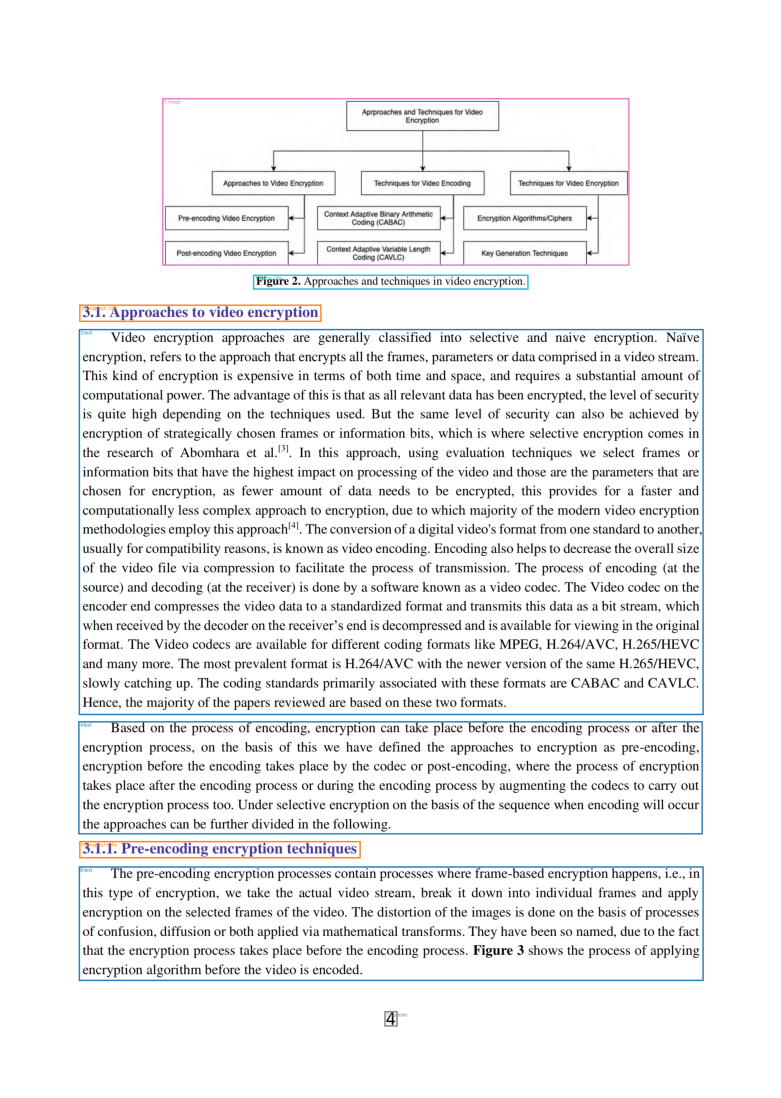

In [17]:
from PIL import Image, ImageDraw

PALETTE = {"doc_title": "#d62728", "paragraph_title": "#ff7f0e", "text": "#1f77b4",
           "table": "#2ca02c", "image": "#9467bd", "formula": "#8c564b",
           "header": "#7f7f7f", "footer": "#7f7f7f", "number": "#7f7f7f"}

def draw_blocks(page, show=True, save_to=None):
    im = Image.open(page["image"]).convert("RGB")
    dr = ImageDraw.Draw(im)
    for b in page["blocks"]:
        if not b["bbox"]:
            continue
        col = "#e377c2" if b["empty"] else PALETTE.get(b["type"], "#17becf")
        dr.rectangle(b["bbox"], outline=col, width=3)
        dr.text((b["bbox"][0] + 4, b["bbox"][1] + 2), f"{b['order']}:{b['type']}", fill=col)
    if save_to:
        im.save(save_to)
    if show:
        plt.figure(figsize=(10, 14)); plt.imshow(im); plt.axis("off"); plt.show()

if document["pages"]:
    draw_blocks(document["pages"][3])

In [13]:
if document["pages"]:
    for b in document["pages"][3]["blocks"]:
        preview = (b["text"] or "").replace("\n", " ")[:110]
        print(f"[{b['order']:>2}] {b['type']:<15} {b['bbox']}  {preview}")

[ 0] image           [330, 191, 1343, 554]  
[ 1] figure_title    [527, 574, 1124, 606]  Figure 2. Approaches and techniques in video encryption.
[ 2] paragraph_title [150, 639, 675, 676]  3.1. Approaches to video encryption
[ 3] text            [149, 692, 1504, 1529]  Video encryption approaches are generally classified into selective and naive encryption. Naïve encryption, re
[ 4] text            [148, 1543, 1502, 1788]  Based on the process of encoding, encryption can take place before the encoding process or after the encryptio
[ 5] paragraph_title [150, 1803, 760, 1840]  3.1.1. Pre-encoding encryption techniques
[ 6] text            [149, 1858, 1504, 2106]  The pre-encoding encryption processes contain processes where frame-based encryption happens, i.e., in this ty
[ 7] number          [812, 2172, 840, 2205]  4


## Bước tiếp theo
`work/document.json` là đầu vào cho các giai đoạn sau: LLM so khớp text với ảnh crop và đánh cảnh báo (không ghi đè), rồi LLM mô tả bố cục và renderer `python-docx` dựng Word.